# Применение машинного обучения для оксида углерода (CO) (регрессия)
# Анализ учитывает пункты наблюдения

In [ ]:
#!pip install shap

### График корреляции оксида углерода с другими признаками

/tmp/ipython-input-4291111948.py:77: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_model[col].fillna(df_model[col].median(), inplace=True)



Размер итоговой выборки: 744041 строк, 24 признаков.


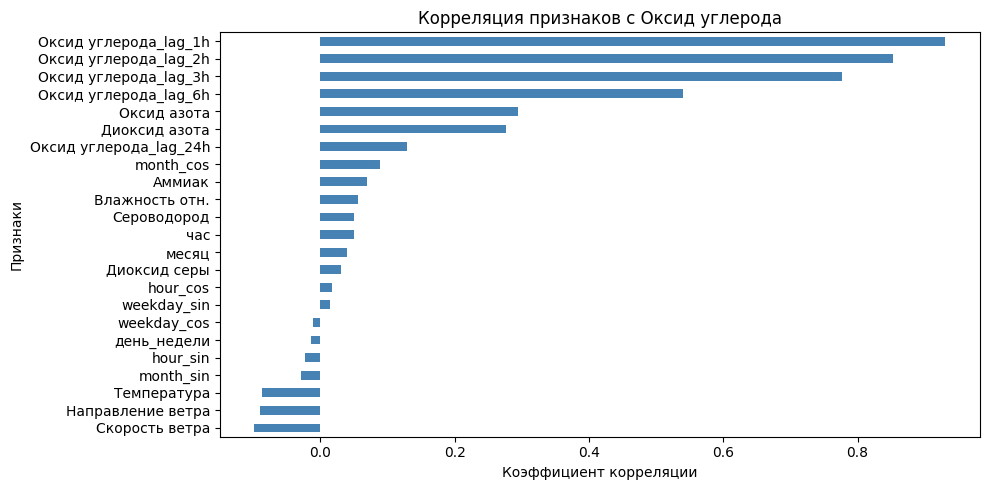

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# --- Шаг 1: Загрузка и объединение данных ---
filenames = [
    "st_01", "st_02", "st_05", "st_07", "st_09",
    "st_26", "st_27", "tr_03", "tr_04", "tr_05", "tr_06"
]

all_dfs = []
for name in filenames:
    try:
        file_path = name + ".csv"
        df_station = pd.read_csv(file_path, encoding="cp1251", sep=";")
        df_station['station_id'] = name  # Добавляем ID станции
        all_dfs.append(df_station)
    except FileNotFoundError:
        print(f"Файл {file_path} не найден, пропускаем.")
        continue

if len(all_dfs) == 0:
    raise SystemExit("Нет загруженных CSV файлов!")

full_df = pd.concat(all_dfs, ignore_index=True)

# --- Шаг 2: Базовая обработка данных ---
full_df['Время'] = pd.to_datetime(full_df['Время'], dayfirst=True, errors='coerce')
full_df.dropna(subset=['Время'], inplace=True)
full_df.set_index('Время', inplace=True)
full_df.sort_index(inplace=True)

TARGET = 'Оксид углерода'

# --- Шаг 3: Корреляционный анализ ---
numeric_df = full_df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()
target_correlation = correlation_matrix[TARGET].sort_values(ascending=False)

# --- Шаг 4: Создание признаков ---
df = full_df.copy()
df['час'] = df.index.hour
df['день_недели'] = df.index.dayofweek  # 0 = понедельник, 6 = воскресенье
df['месяц'] = df.index.month

# --- Циклическое кодирование времени ---
df['hour_sin'] = np.sin(2 * np.pi * df['час'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['час'] / 24)
df['weekday_sin'] = np.sin(2 * np.pi * df['день_недели'] / 7)
df['weekday_cos'] = np.cos(2 * np.pi * df['день_недели'] / 7)
df['month_sin'] = np.sin(2 * np.pi * df['месяц'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['месяц'] / 12)

# --- Лаговые признаки ---
lags = [1, 2, 3, 6, 24]
for lag in lags:
    df[f'{TARGET}_lag_{lag}h'] = df.groupby('station_id')[TARGET].shift(lag)

# --- Шаг 5: Финальная подготовка к обучению ---
df_model = df.copy()
min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
if 'Номер' in df_model.columns:
    df_model = df_model.drop(columns=['Номер'])

# Импутация медианой по каждой колонке
numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    df_model[col].fillna(df_model[col].median(), inplace=True)

df_model.dropna(inplace=True)
y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")

# --- График корреляции признаков с целевой переменной ---
corr_with_target = df_model.corr(numeric_only=True)[TARGET].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
corr_with_target.drop(TARGET).plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()  # чтобы самые сильные корреляции были сверху
plt.title(f'Корреляция признаков с {TARGET}')
plt.xlabel('Коэффициент корреляции')
plt.ylabel('Признаки')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# --- Шаг 1: Загрузка и объединение данных ---
filenames = [
    "st_01", "st_02", "st_05", "st_07", "st_09",
    "st_26", "st_27", "tr_03", "tr_04", "tr_05", "tr_06"
]

all_dfs = []
for name in filenames:
    try:
        file_path = name + ".csv"
        df_station = pd.read_csv(file_path, encoding="cp1251", sep=";")
        df_station['station_id'] = name  # Добавляем ID станции
        all_dfs.append(df_station)
    except FileNotFoundError:
        print(f"Файл {file_path} не найден, пропускаем.")
        continue

if len(all_dfs) == 0:
    raise SystemExit("Нет загруженных CSV файлов!")

full_df = pd.concat(all_dfs, ignore_index=True)

# --- Шаг 2: Базовая обработка данных ---
full_df['Время'] = pd.to_datetime(full_df['Время'], dayfirst=True, errors='coerce')
full_df.dropna(subset=['Время'], inplace=True)
full_df.set_index('Время', inplace=True)
full_df.sort_index(inplace=True)

TARGET = 'Оксид углерода'

# --- Шаг 3: Корреляционный анализ ---
numeric_df = full_df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()
target_correlation = correlation_matrix[TARGET].sort_values(ascending=False)

# --- Шаг 4: Создание признаков ---
df = full_df.copy()
df['час'] = df.index.hour
df['день_недели'] = df.index.dayofweek  # 0 = понедельник, 6 = воскресенье
df['месяц'] = df.index.month

# --- Циклическое кодирование времени ---
df['hour_sin'] = np.sin(2 * np.pi * df['час'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['час'] / 24)
df['weekday_sin'] = np.sin(2 * np.pi * df['день_недели'] / 7)
df['weekday_cos'] = np.cos(2 * np.pi * df['день_недели'] / 7)
df['month_sin'] = np.sin(2 * np.pi * df['месяц'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['месяц'] / 12)

# --- Лаговые признаки ---
lags = [1, 2, 3, 6, 24]
for lag in lags:
    df[f'{TARGET}_lag_{lag}h'] = df.groupby('station_id')[TARGET].shift(lag)

# --- Шаг 5: Финальная подготовка к обучению ---
df_model = df.copy()
min_valid_values = len(df_model) * 0.5
df_model = df_model.dropna(axis='columns', thresh=min_valid_values)
if 'Номер' in df_model.columns:
    df_model = df_model.drop(columns=['Номер'])

# Импутация медианой по каждой колонке
numeric_cols = df_model.select_dtypes(include=np.number).columns
for col in numeric_cols:
    df_model[col].fillna(df_model[col].median(), inplace=True)

df_model.dropna(inplace=True)
y = df_model[TARGET]
X = df_model.drop(columns=[TARGET])

print(f"\nРазмер итоговой выборки: {X.shape[0]} строк, {X.shape[1]} признаков.")

# --- Шаг 6: Разделение данных и обучение модели ---
train_size = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), ['station_id'])],
    remainder='passthrough'
)

print("\n--- Обучение модели RandomForestRegressor ---")
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, min_samples_leaf=5))
])
model_pipeline.fit(X_train_raw, y_train)

# --- Шаг 7: Оценка модели ---
predictions = model_pipeline.predict(X_test_raw)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"\nКачество модели на тестовых данных:")
print(f"MAE: {mae:.4f}, RMSE: {rmse:.4f}, R2: {r2:.4f}")

/tmp/ipython-input-4026858765.py:77: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_model[col].fillna(df_model[col].median(), inplace=True)



Размер итоговой выборки: 744041 строк, 24 признаков.

--- Обучение модели RandomForestRegressor ---

Качество модели на тестовых данных:
MAE: 0.0565, RMSE: 0.1554, R2: 0.8634


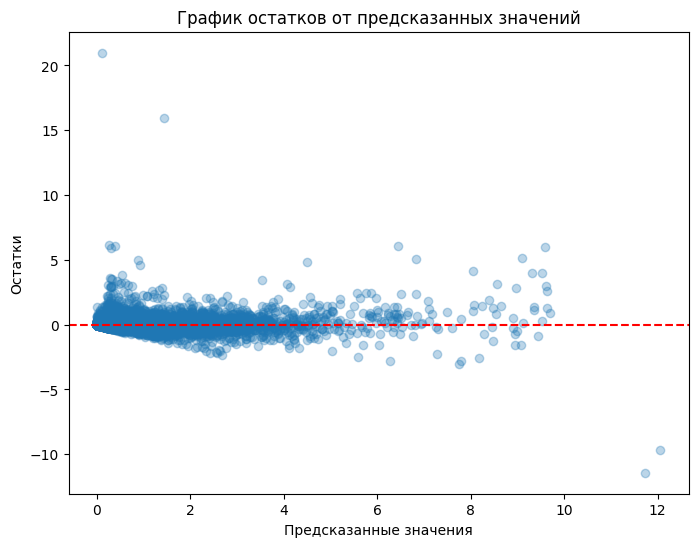

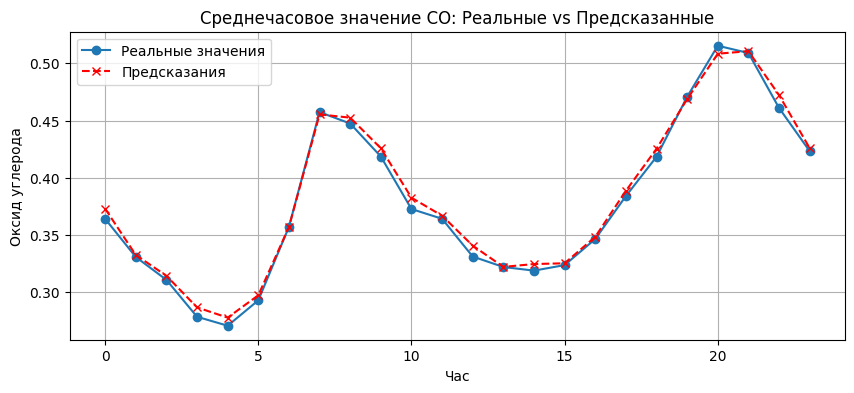

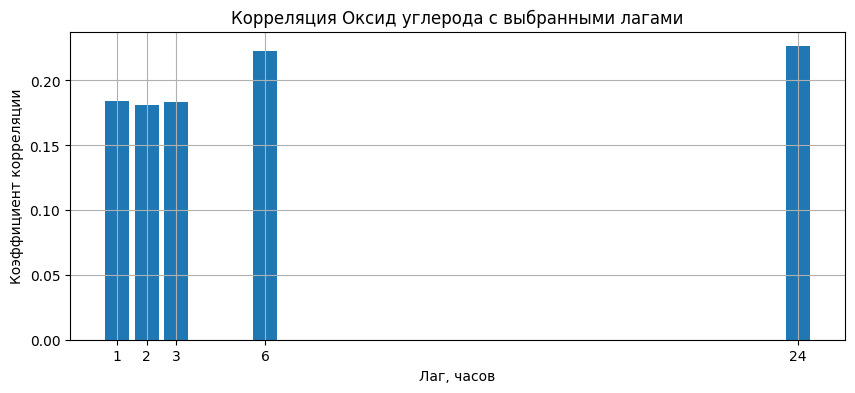


--- Анализ пиков (>90 перцентиля) ---
MAE на пиках: 0.1940
RMSE на пиках: 0.4336
Количество пиков: 14879 (10.0% выборки)


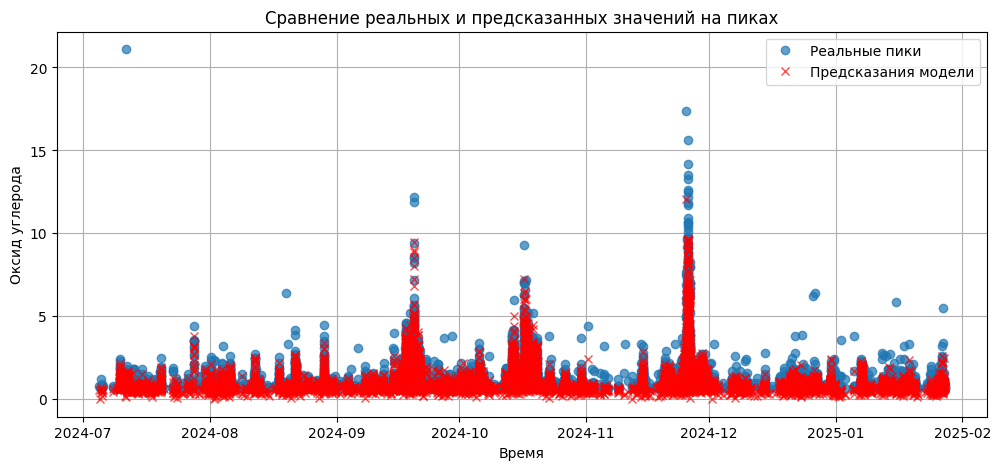

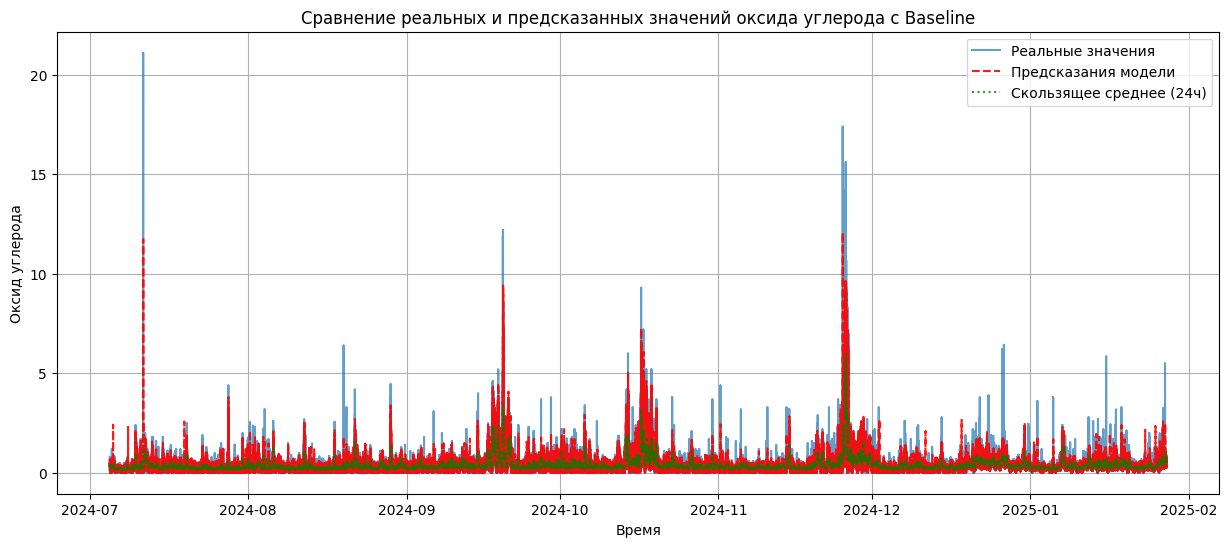

In [ ]:
# --- Остатки vs Предсказания ---
residuals = y_test - predictions

plt.figure(figsize=(8,6))
plt.scatter(predictions, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('График остатков от предсказанных значений')
plt.show()

# --- Часовой / суточный график ---
# Создаем DataFrame для удобства группировки и построения графиков
df_test_results = pd.DataFrame({
    TARGET: y_test,
    'Предсказания': predictions,
    'час': y_test.index.hour,
    'месяц': y_test.index.month
})

hourly_mean_real = df_test_results.groupby('час')[TARGET].mean()
hourly_mean_pred = df_test_results.groupby('час')['Предсказания'].mean()

plt.figure(figsize=(10,4))
plt.plot(hourly_mean_real.index, hourly_mean_real.values, marker='o', label='Реальные значения')
plt.plot(hourly_mean_pred.index, hourly_mean_pred.values, marker='x', linestyle='--', label='Предсказания', color='red')
plt.title('Среднечасовое значение CO: Реальные vs Предсказанные')
plt.xlabel('Час')
plt.ylabel(TARGET)
plt.legend()
plt.grid(True)
plt.show()

# --- Анализ лагов ---
# Используем только те лаги, которые были созданы как признаки
selected_lags = [1, 2, 3, 6, 24]
lag_corrs = []
for lag in selected_lags:
    lag_corrs.append(df_model[TARGET].corr(df_model[TARGET].shift(lag)))

plt.figure(figsize=(10, 4))
plt.bar(selected_lags, lag_corrs)
plt.title(f'Корреляция {TARGET} с выбранными лагами')
plt.xlabel('Лаг, часов')
plt.ylabel('Коэффициент корреляции')
plt.xticks(selected_lags) # Устанавливаем метки только для выбранных лагов
plt.grid(True)
plt.show()

# --- Анализ пиков ---
threshold = np.percentile(y_test, 90)
peaks_mask = y_test > threshold
y_test_peaks = y_test[peaks_mask]
pred_peaks = pd.Series(predictions, index=y_test.index)[peaks_mask]

mae_peaks = mean_absolute_error(y_test_peaks, pred_peaks)
rmse_peaks = np.sqrt(mean_squared_error(y_test_peaks, pred_peaks))

print(f"\n--- Анализ пиков (>90 перцентиля) ---")
print(f"MAE на пиках: {mae_peaks:.4f}")
print(f"RMSE на пиках: {rmse_peaks:.4f}")
print(f"Количество пиков: {len(y_test_peaks)} ({len(y_test_peaks)/len(y_test)*100:.1f}% выборки)")

plt.figure(figsize=(12, 5))
plt.plot(y_test_peaks.index, y_test_peaks, 'o', label='Реальные пики', alpha=0.7)
plt.plot(pred_peaks.index, pred_peaks, 'x', label='Предсказания модели', alpha=0.7, color='red')
plt.title('Сравнение реальных и предсказанных значений на пиках')
plt.xlabel('Время')
plt.ylabel(TARGET)
plt.legend()
plt.grid(True)
plt.show()

# --- График реальных vs предсказанных с baseline ---
# Добавляем этот график сюда, так как в ячейке 12d5a455 он был основным после обучения
plt.figure(figsize=(15,6))
plt.plot(y_test.index, y_test, label='Реальные значения', alpha=0.7)
plt.plot(y_test.index, predictions, label='Предсказания модели', linestyle='--', alpha=0.9, color='red')

# Расчет и добавление простого baseline (скользящее среднее за 24 часа)
# Применяем rolling mean к y_test
rolling_avg_24h = y_test.rolling(window=24, min_periods=1).mean()
plt.plot(rolling_avg_24h.index, rolling_avg_24h, label='Скользящее среднее (24ч)', color='green', linestyle=':', alpha=0.8)

plt.title('Сравнение реальных и предсказанных значений оксида углерода с Baseline')
plt.xlabel('Время')
plt.ylabel(TARGET)
plt.legend()
plt.grid(True)
plt.show()


--- Графики реальных vs предсказанных по каждой станции ---

Строим график для станции: st_05


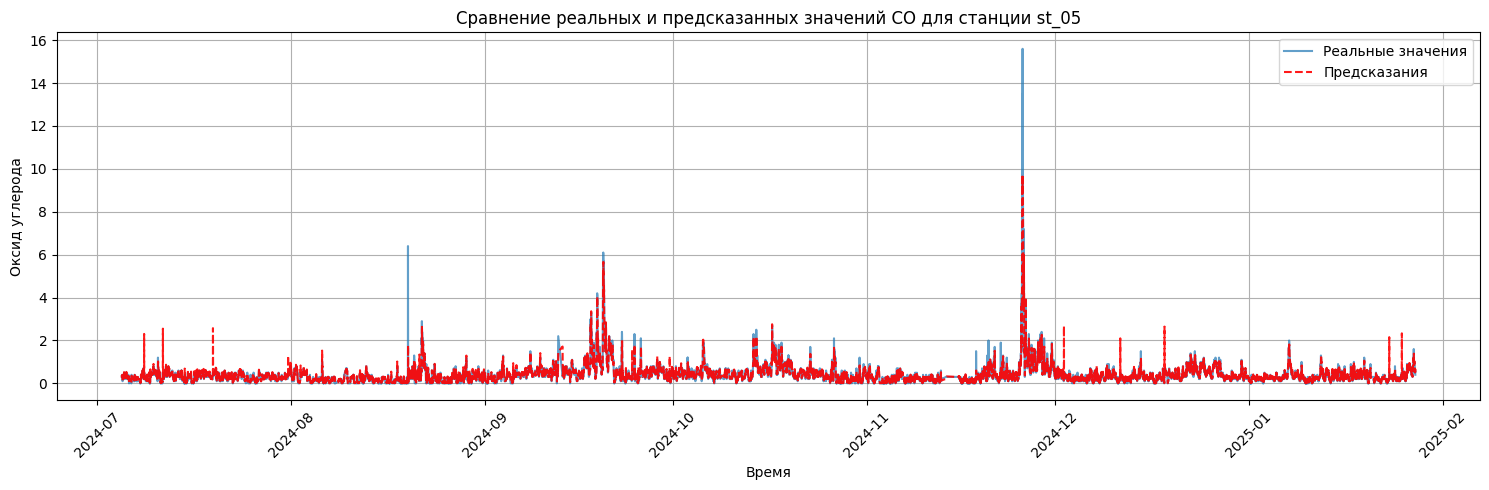


Строим график для станции: st_27


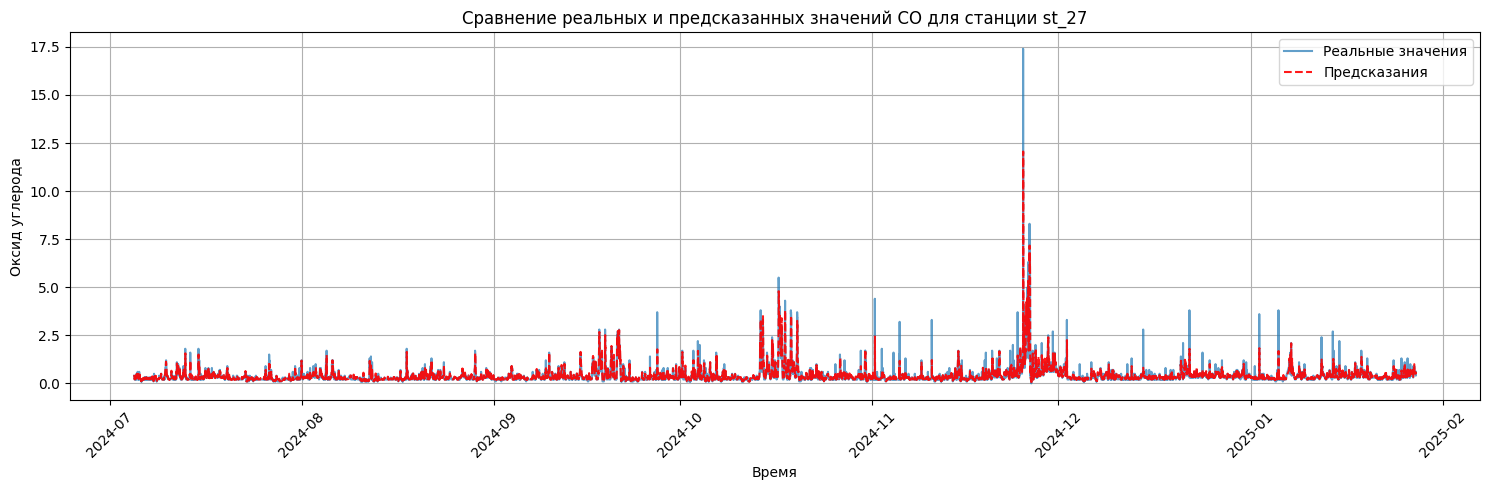


Строим график для станции: st_02


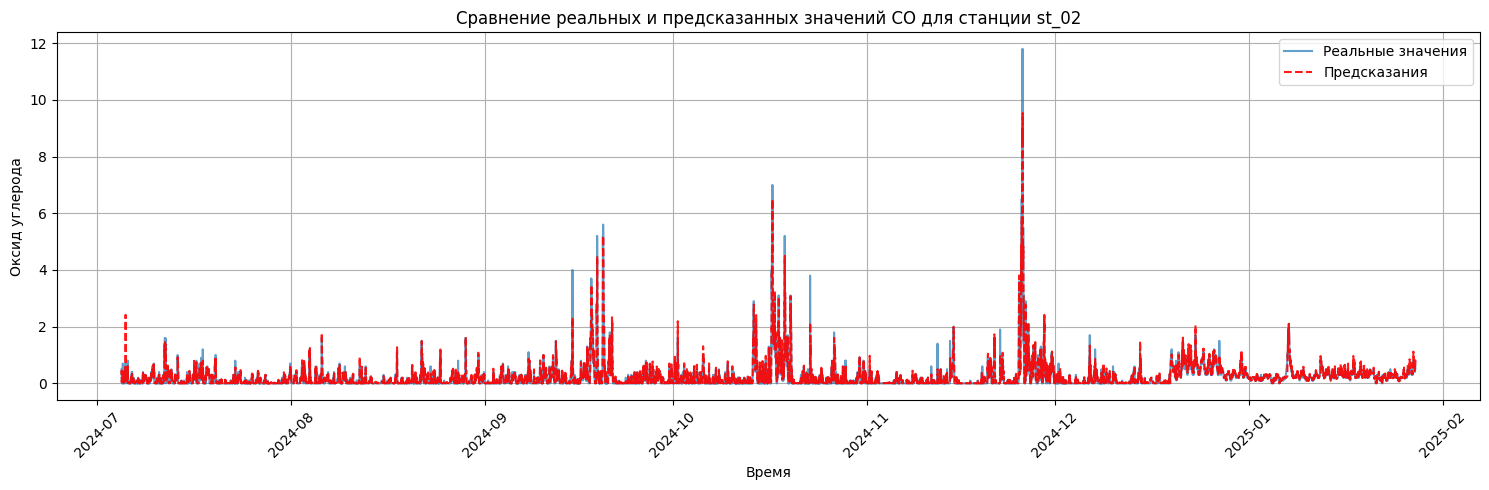


Строим график для станции: st_26


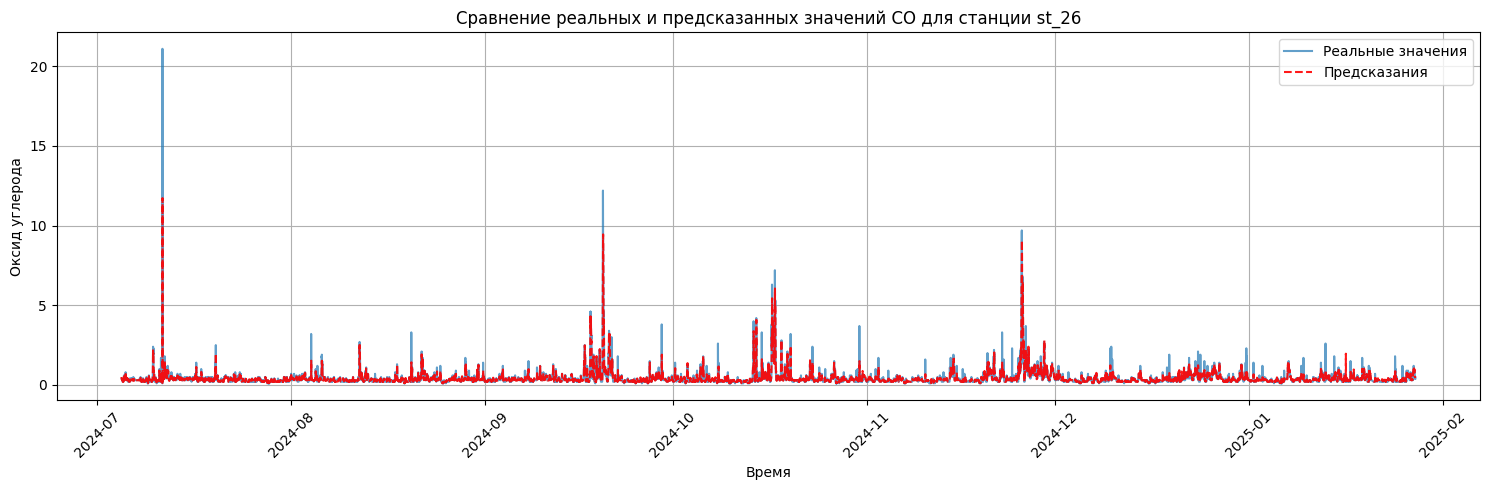


Строим график для станции: st_01


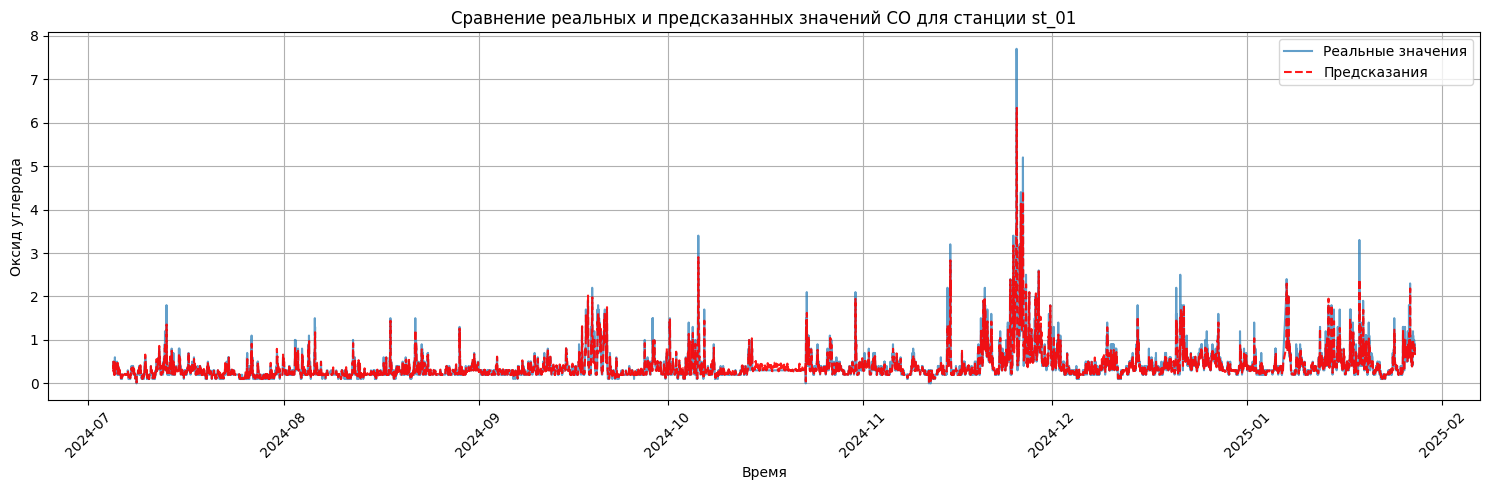


Строим график для станции: st_07


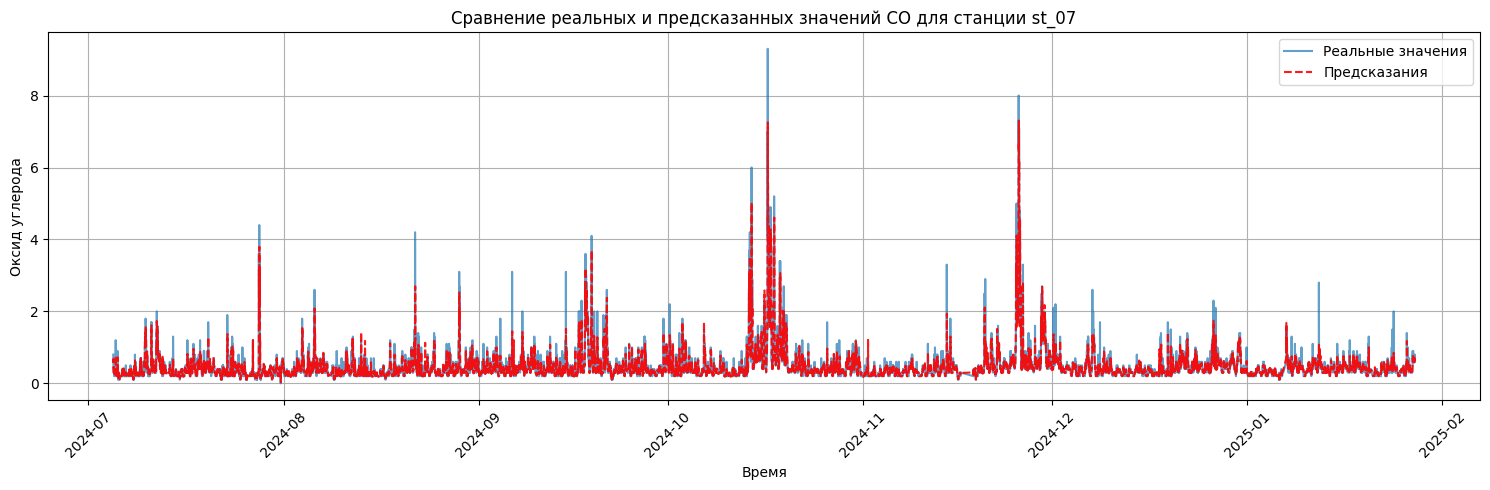


Строим график для станции: st_09


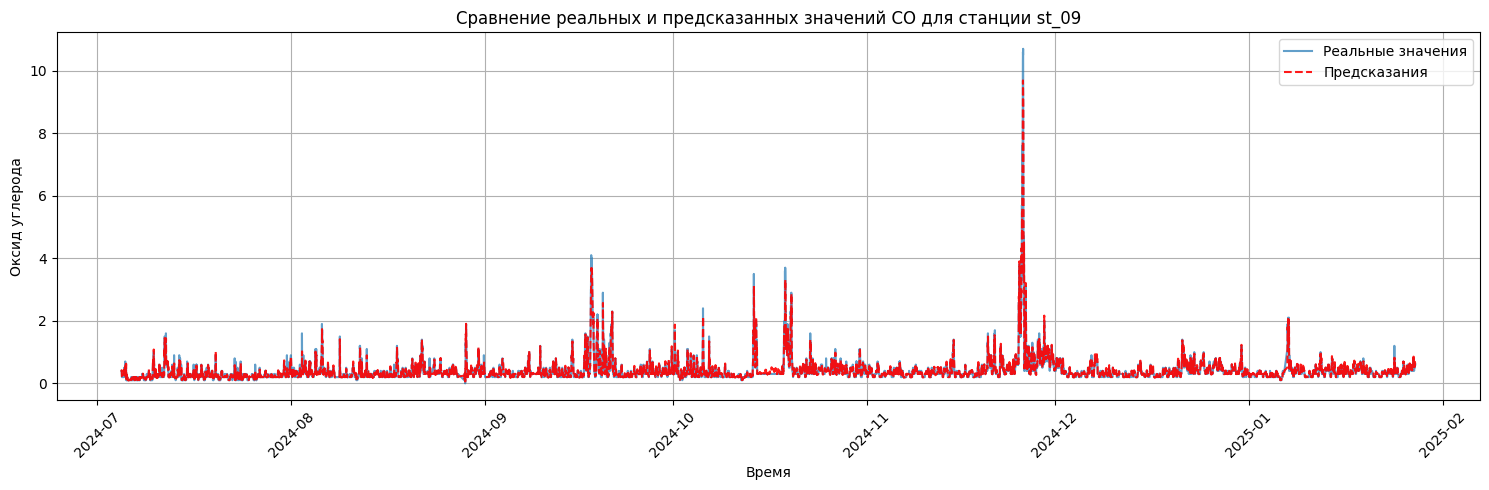


Строим график для станции: tr_03


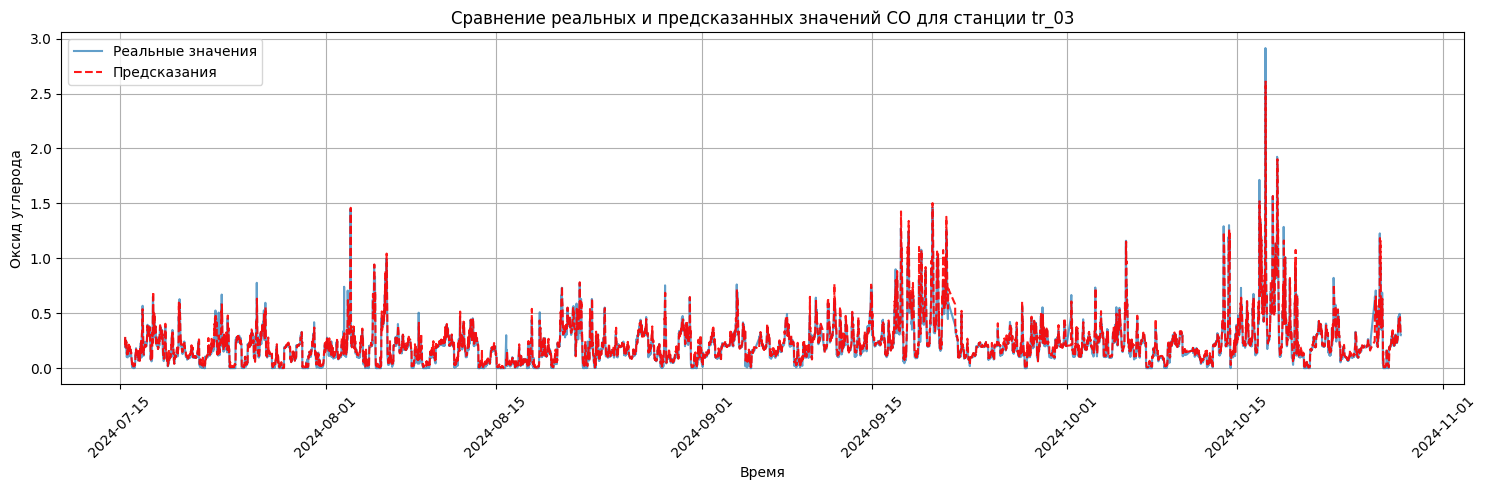


Строим график для станции: tr_06


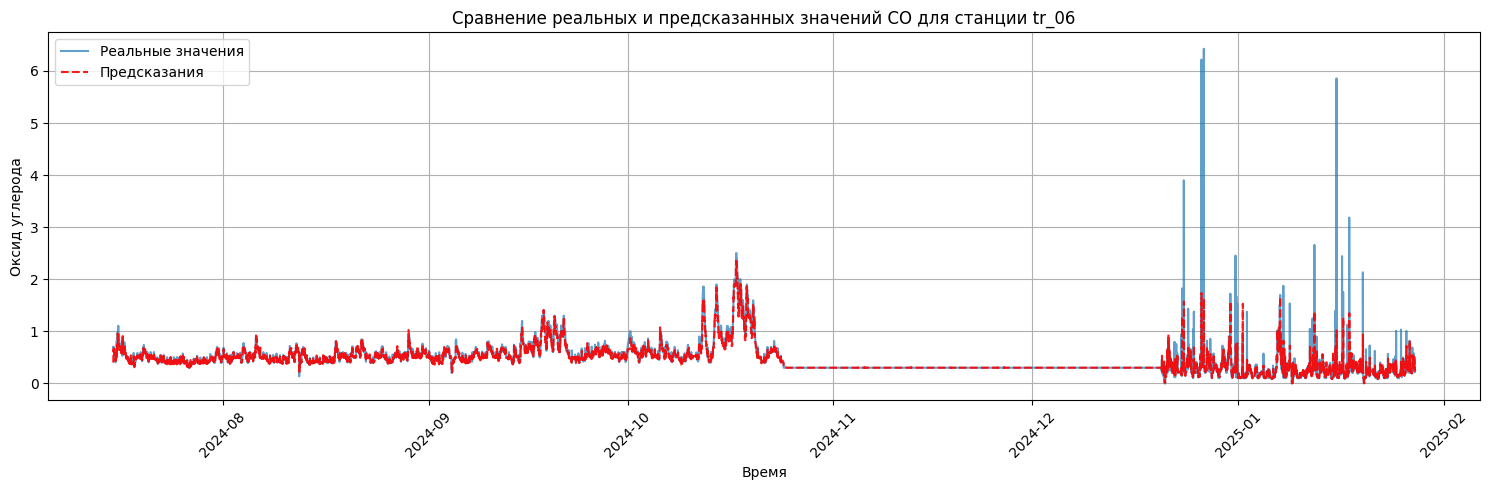


Строим график для станции: tr_04


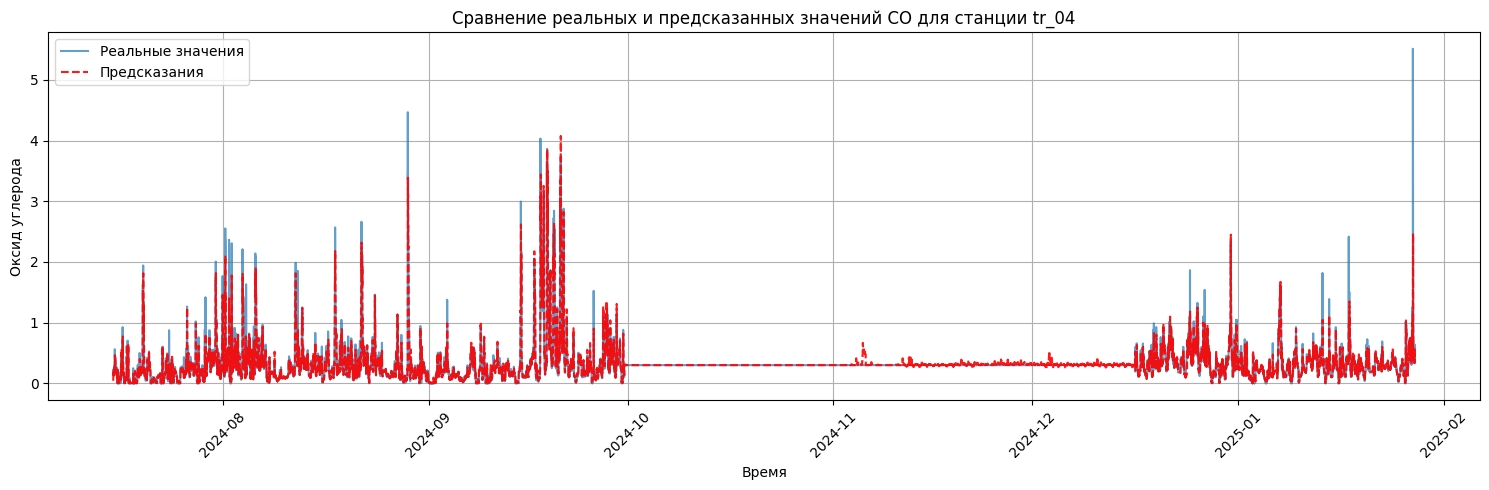


Строим график для станции: tr_05


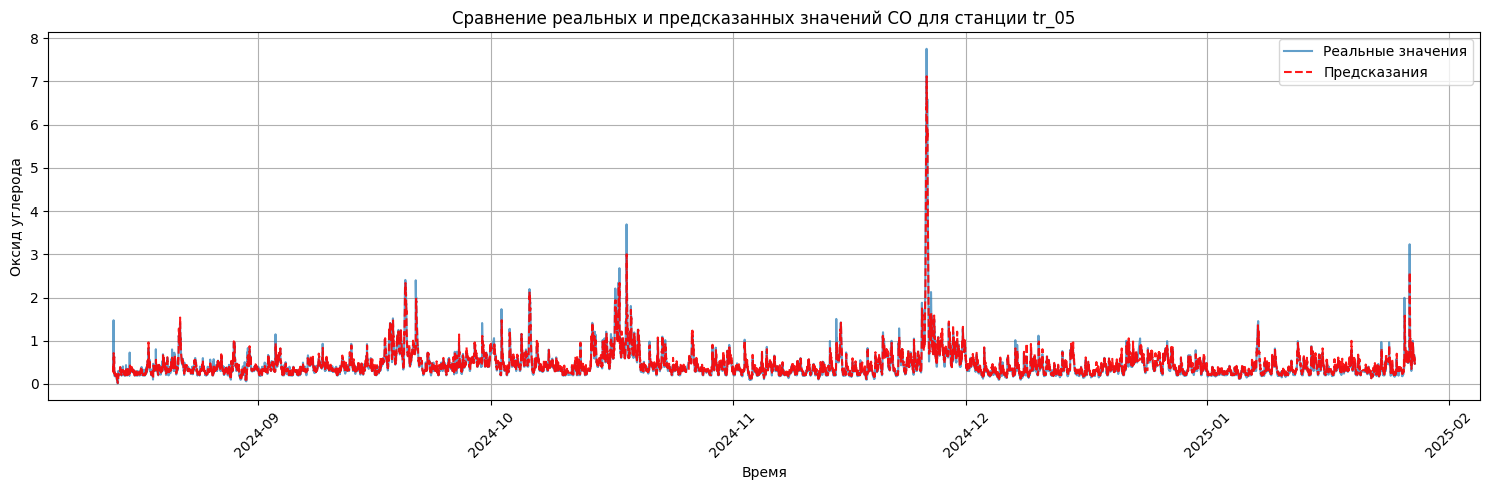

In [ ]:
# --- Графики сравнения реальных vs предсказанных по станциям ---

# Преобразуем предсказания в Series с тем же индексом, что и y_test
predictions_series = pd.Series(predictions, index=y_test.index)

# Объединяем все данные в один DataFrame для согласованной индексации
test_data = pd.DataFrame({
    'y_true': y_test,
    'y_pred': predictions_series,
    'station_id': X_test_raw['station_id'].values  # берём значения, а не индекс
}, index=y_test.index)  # используем индекс y_test как основной

unique_stations = test_data['station_id'].unique()

print("\n--- Графики реальных vs предсказанных по каждой станции ---")

for station in unique_stations:
    print(f"\nСтроим график для станции: {station}")

    # Фильтруем данные для текущей станции
    station_data = test_data[test_data['station_id'] == station]

    if station_data.empty:
        print(f"Нет данных для станции {station} в тестовой выборке.")
        continue

    plt.figure(figsize=(15, 5))
    plt.plot(station_data.index, station_data['y_true'],
             label='Реальные значения', alpha=0.7)
    plt.plot(station_data.index, station_data['y_pred'],
             label='Предсказания', linestyle='--', alpha=0.9, color='red')
    plt.title(f'Сравнение реальных и предсказанных значений CO для станции {station}')
    plt.xlabel('Время')
    plt.ylabel(TARGET)
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

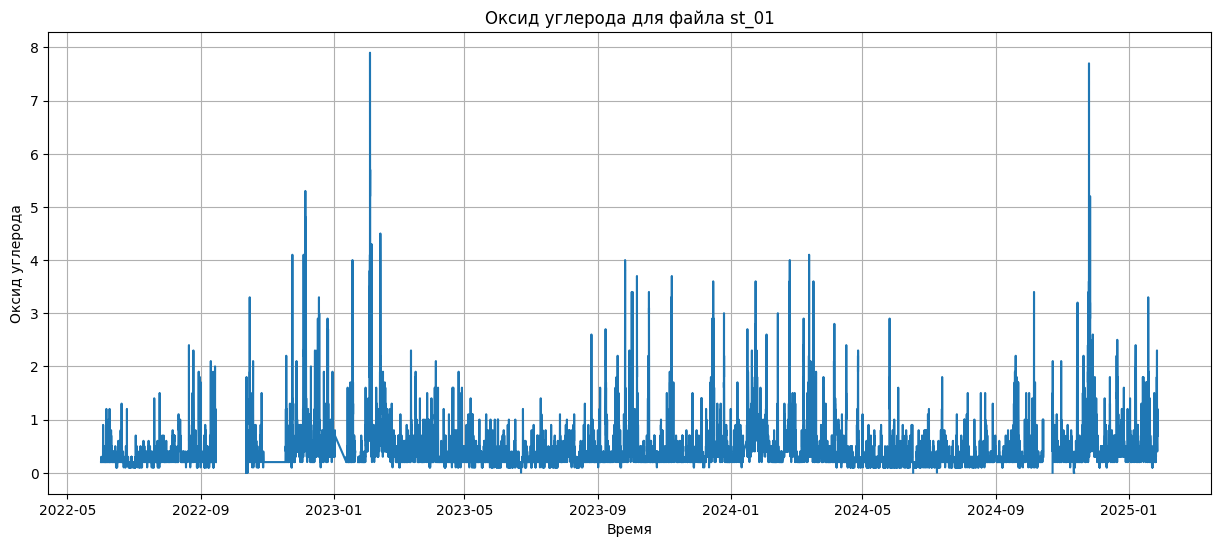

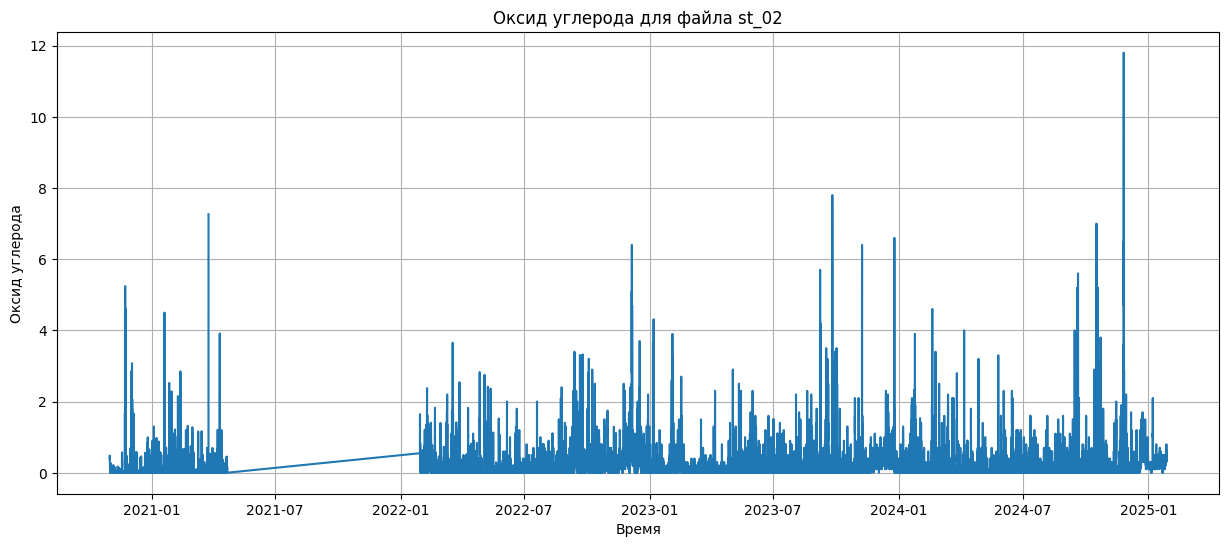

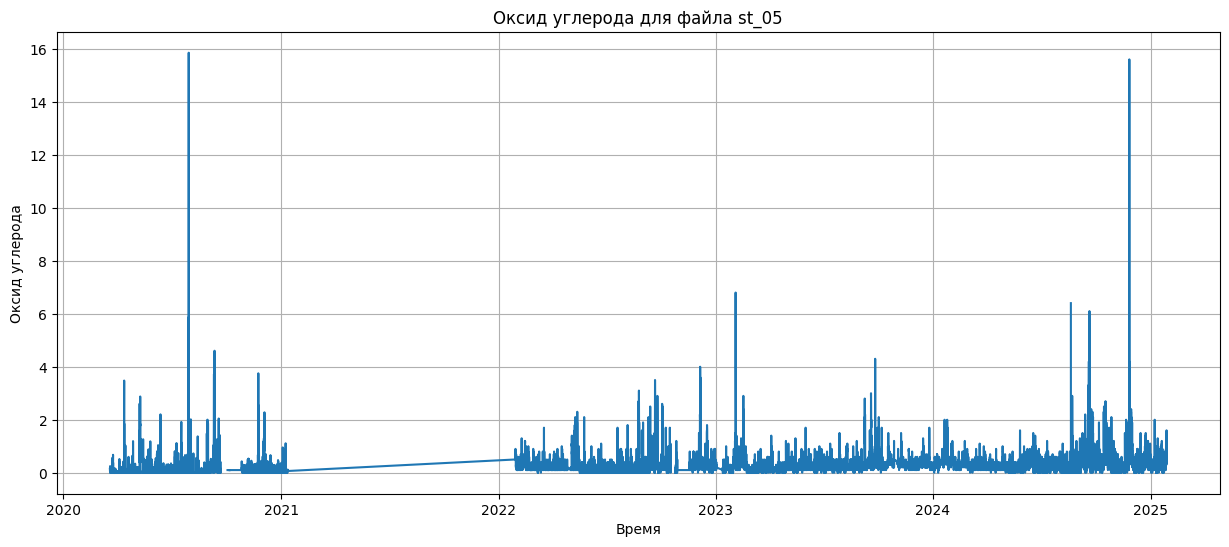

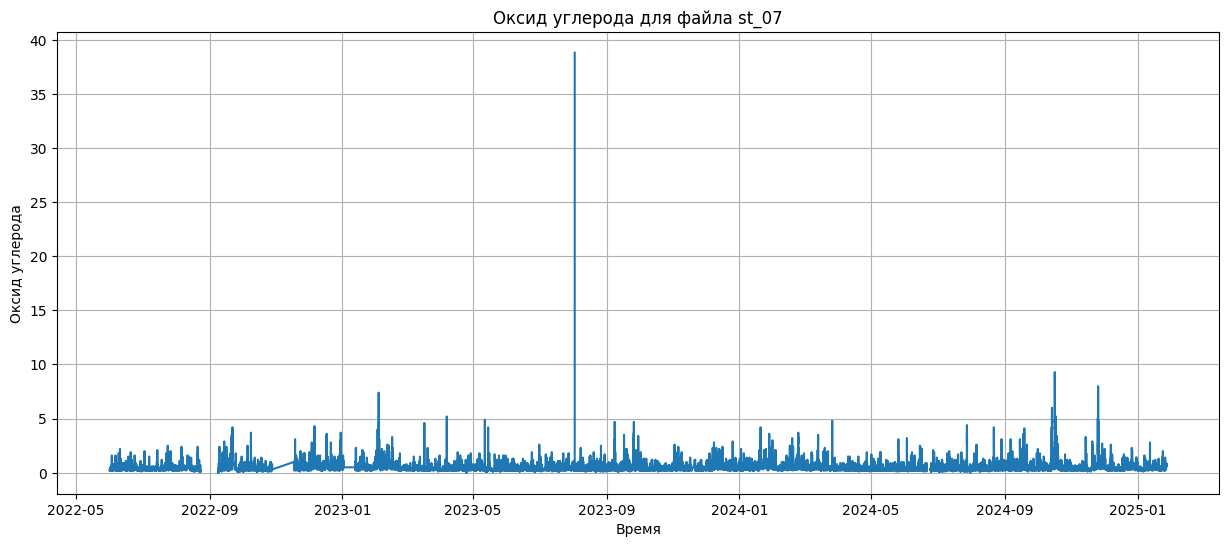

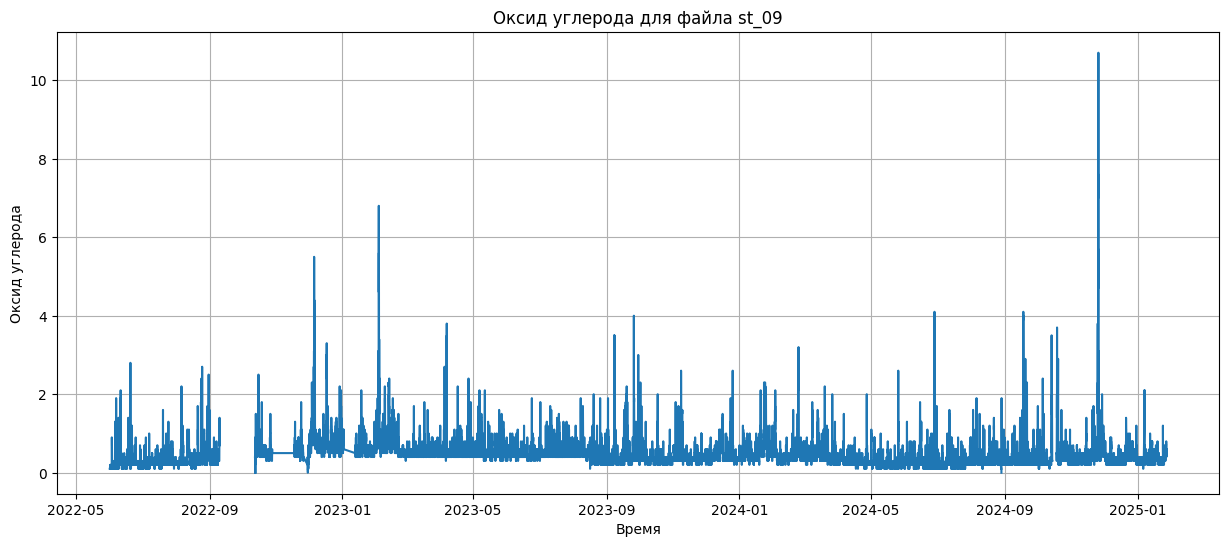

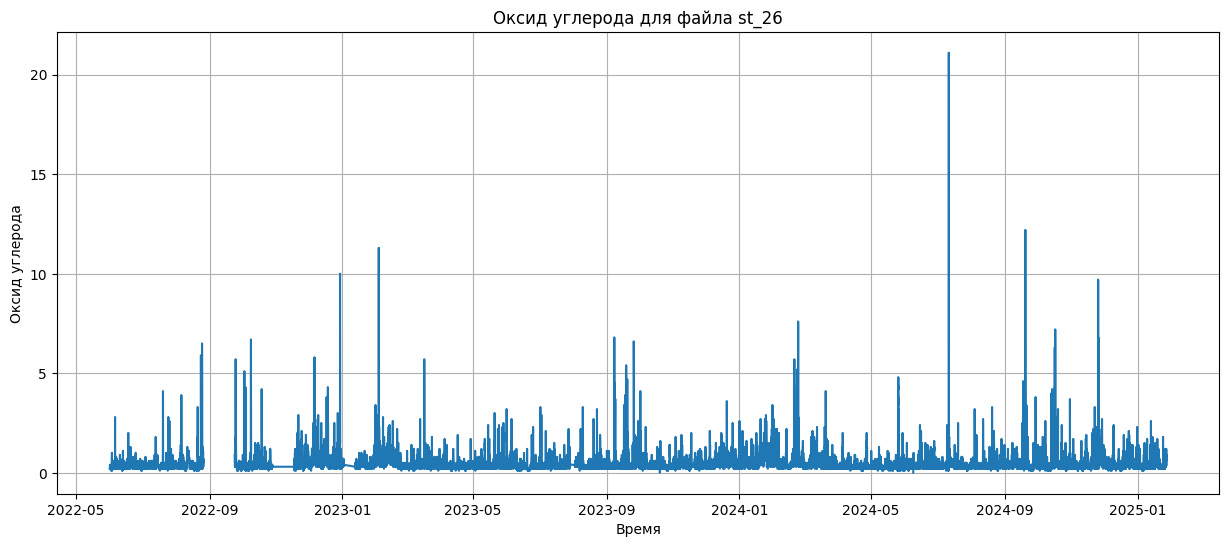

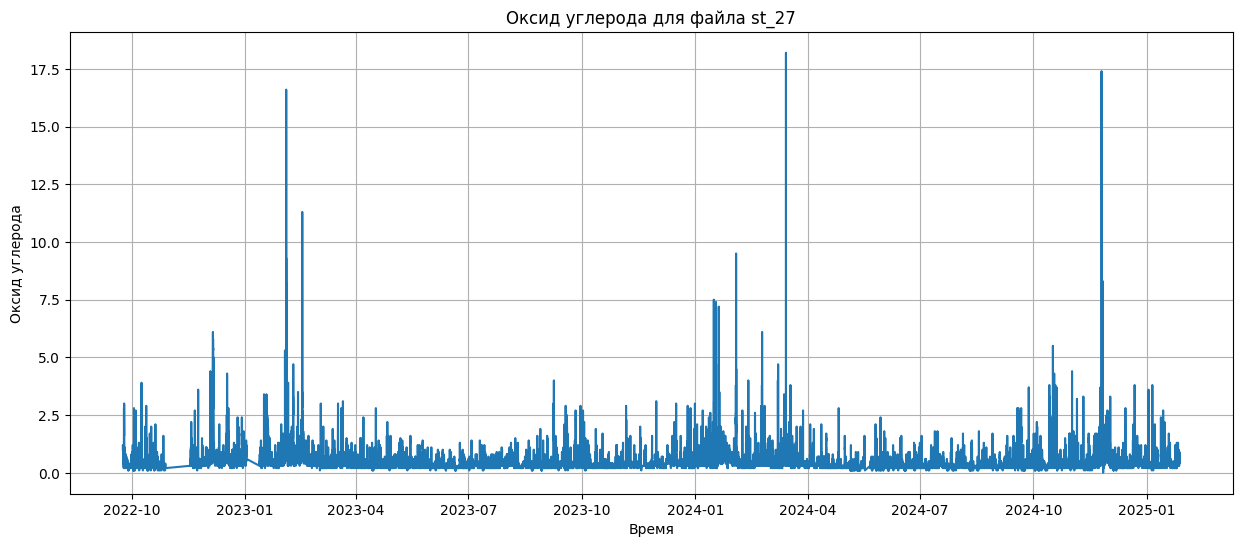

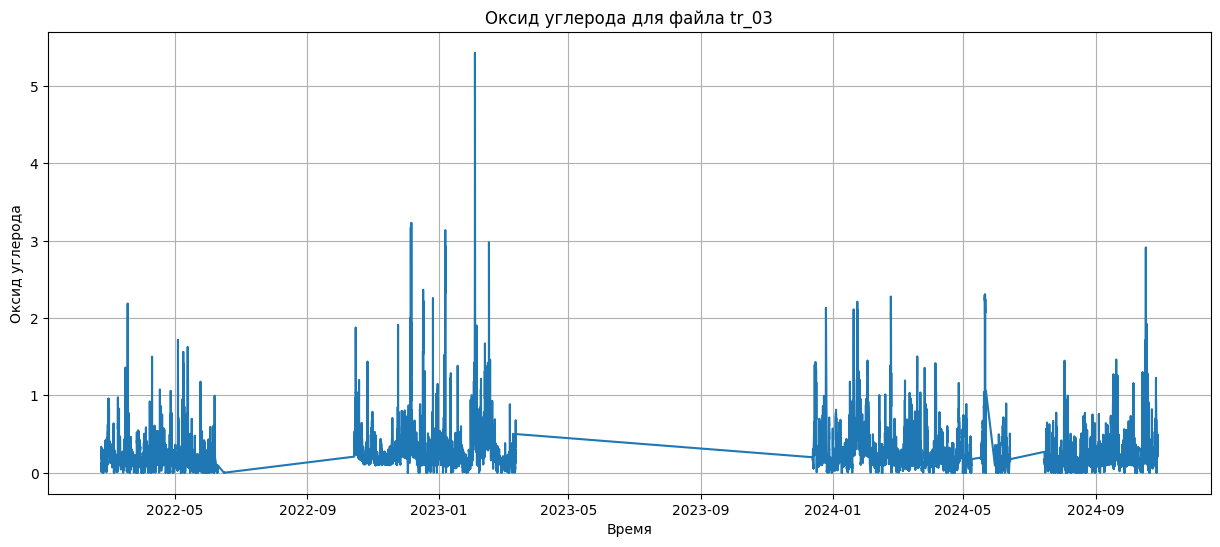

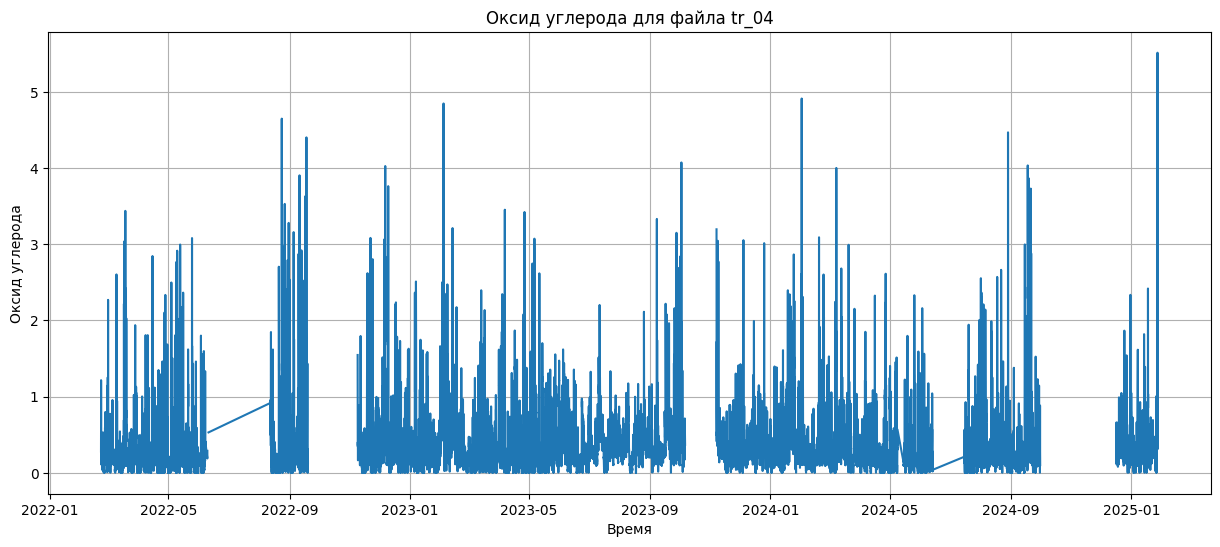

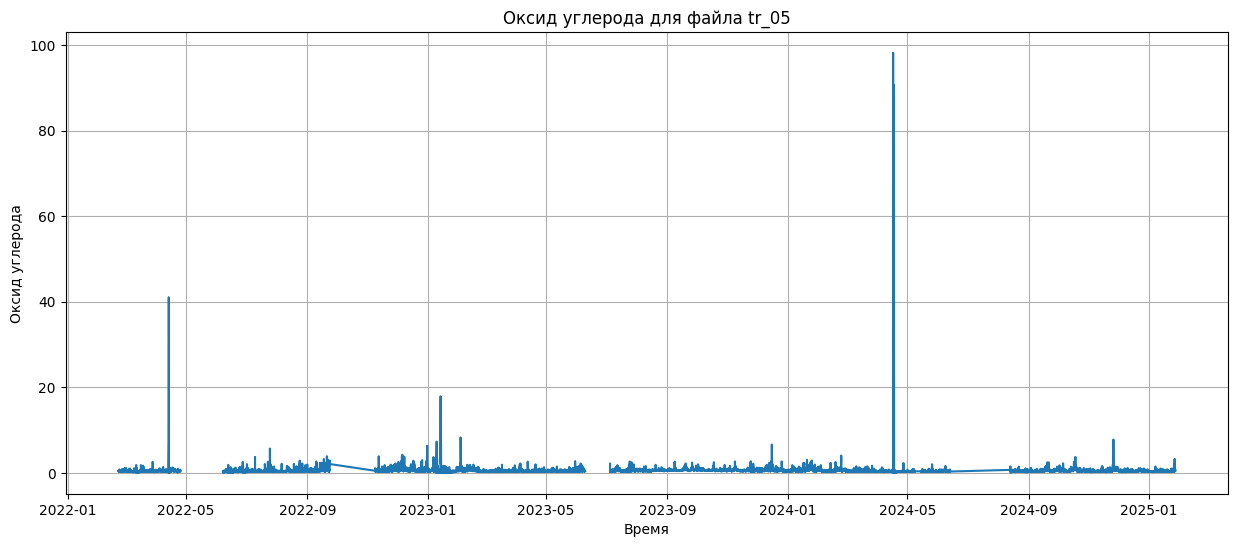

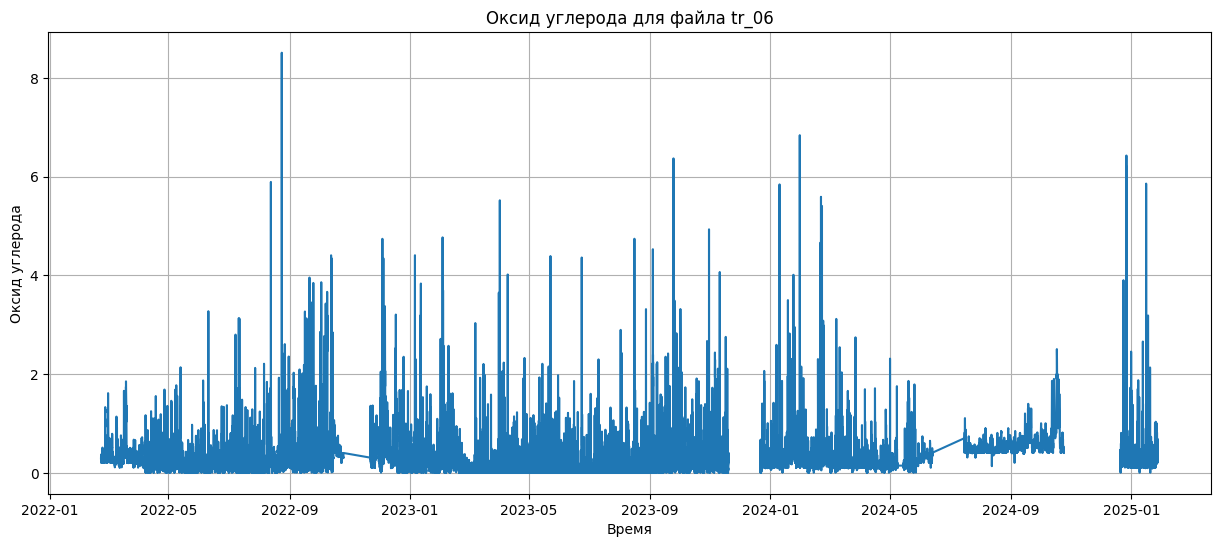

In [ ]:
# --- Визуализация данных по каждой станции ---
for name in filenames:
    df_station = full_df[full_df['station_id'] == name]
    if not df_station.empty:
        plt.figure(figsize=(15, 6))
        plt.plot(df_station.index, df_station[TARGET])
        plt.title(f'{TARGET} для файла {name}')
        plt.xlabel('Время')
        plt.ylabel(TARGET)
        plt.grid(True)
        plt.show()
    else:
        print(f"Нет данных для станции {name}, пропускаем.")


Permutation importance рассчитывается на 50767 строках (из 148809)


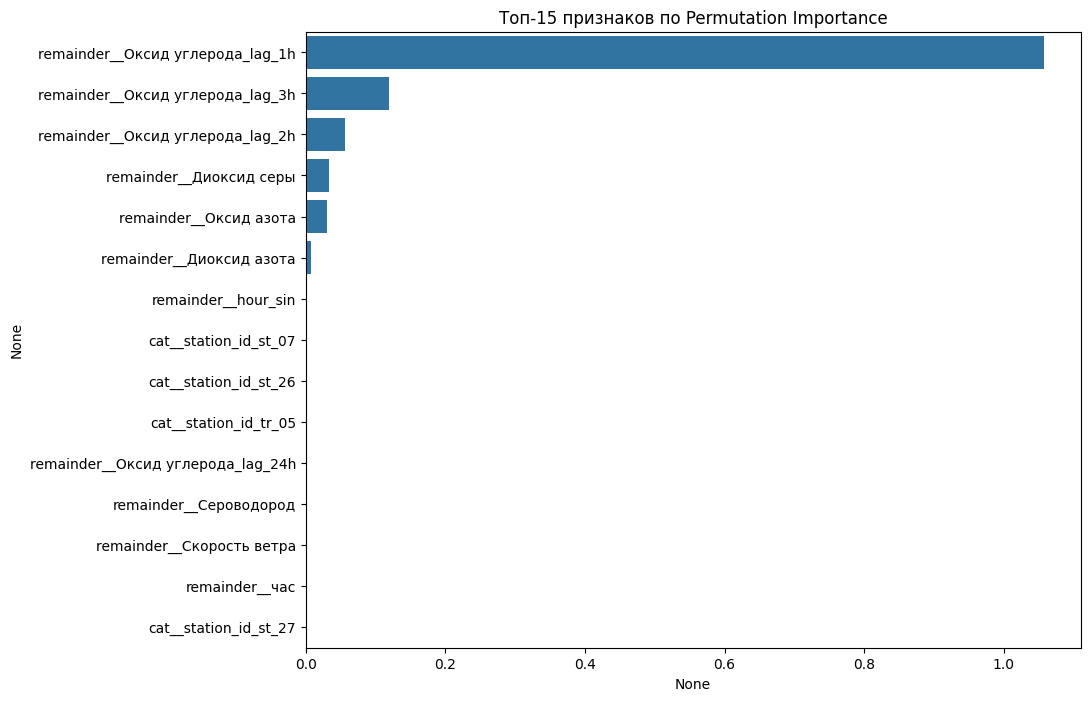

In [ ]:
# --- Permutation importance (важность признаков перестановкой) ---
max_sample_size = 5000  # Дополнительно уменьшаем размер выборки, чтобы избежать проблем с дисковым пространством
if len(X_test_raw) > max_sample_size:
    # Получаем индексы случайно выбранных строк из X_test_raw
    sample_indices = X_test_raw.sample(n=max_sample_size, random_state=42).index
    # Используем эти индексы для выборки и из X_test_raw, и из y_test
    X_test_sample = X_test_raw.loc[sample_indices].sort_index()
    y_test_sample = y_test.loc[sample_indices].sort_index()
else:
    X_test_sample, y_test_sample = X_test_raw, y_test

print(f"\nPermutation importance рассчитывается на {len(X_test_sample)} строках (из {len(X_test_raw)})")

# Применяем препроцессинг вручную к выборке
X_test_sample_processed = model_pipeline.named_steps['preprocessor'].transform(X_test_sample)

# Получаем имена признаков после препроцессинга
processed_feature_names = model_pipeline.named_steps['preprocessor'].get_feature_names_out(X_test_sample.columns)

# Считаем permutation importance по уже обработанным данным и самому регрессору
perm_imp = permutation_importance(
    model_pipeline.named_steps['regressor'],  # используем только регрессор из пайплайна
    X_test_sample_processed,                 # передаём обработанную выборку
    y_test_sample,
    n_repeats=5,
    random_state=42,
    n_jobs=1  # ставим n_jobs=1, чтобы отключить параллельную обработку и избежать проблем с воркерами
)

# Преобразуем в pandas.Series для удобства и сортируем по убыванию
perm_series = pd.Series(perm_imp.importances_mean, index=processed_feature_names).sort_values(ascending=False)

# Строим график топ-15 наиболее важных признаков
plt.figure(figsize=(10, 8))
sns.barplot(x=perm_series.head(15), y=perm_series.head(15).index)
plt.title('Топ-15 признаков по Permutation Importance')
plt.show()


--- Визуализация зависимости от топ-10 ключевых признаков ---

График зависимости 'Оксид углерода' от 'Диоксид серы':


/tmp/ipython-input-4256295902.py:41: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  elif feature in df_model.columns and df_model[feature].dtype in [np.number] and feature != 'station_id':


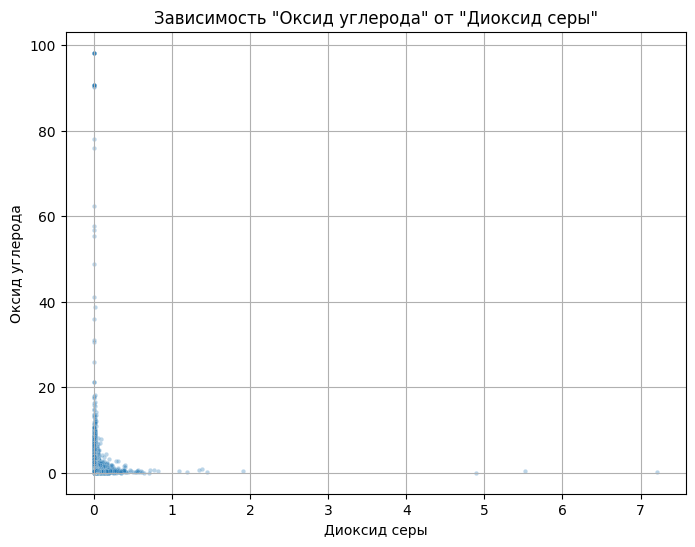


График зависимости 'Оксид углерода' от 'Оксид азота':


/tmp/ipython-input-4256295902.py:41: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  elif feature in df_model.columns and df_model[feature].dtype in [np.number] and feature != 'station_id':


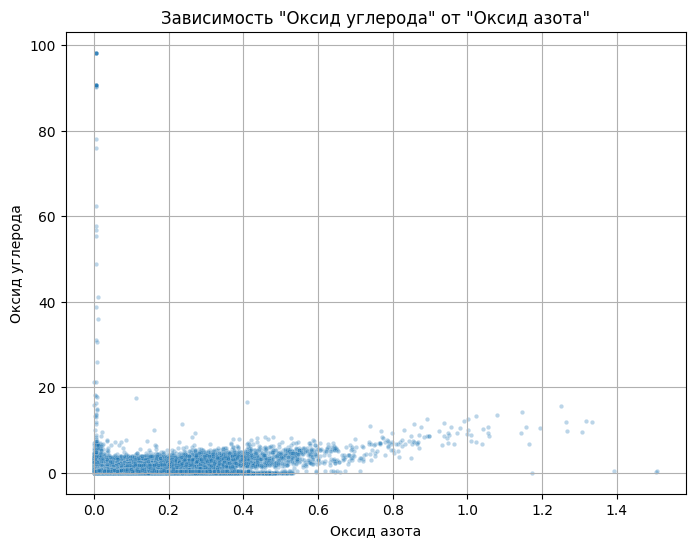


График зависимости 'Оксид углерода' от 'Диоксид азота':


/tmp/ipython-input-4256295902.py:41: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  elif feature in df_model.columns and df_model[feature].dtype in [np.number] and feature != 'station_id':


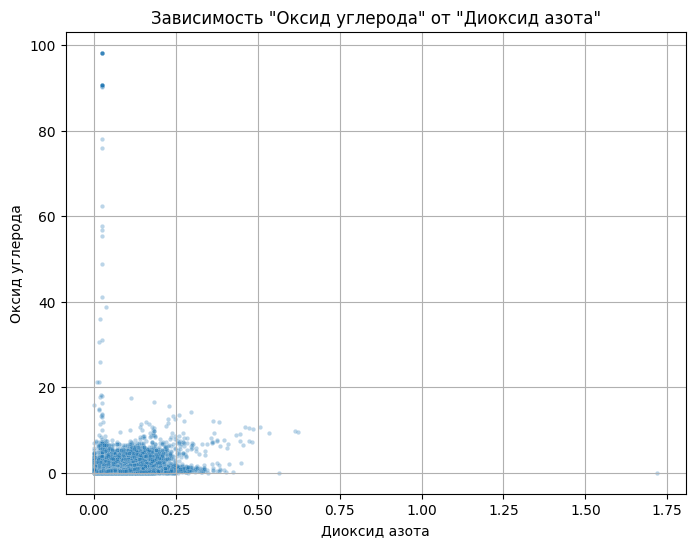


График зависимости 'Оксид углерода' от 'hour_sin':


/tmp/ipython-input-4256295902.py:41: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  elif feature in df_model.columns and df_model[feature].dtype in [np.number] and feature != 'station_id':


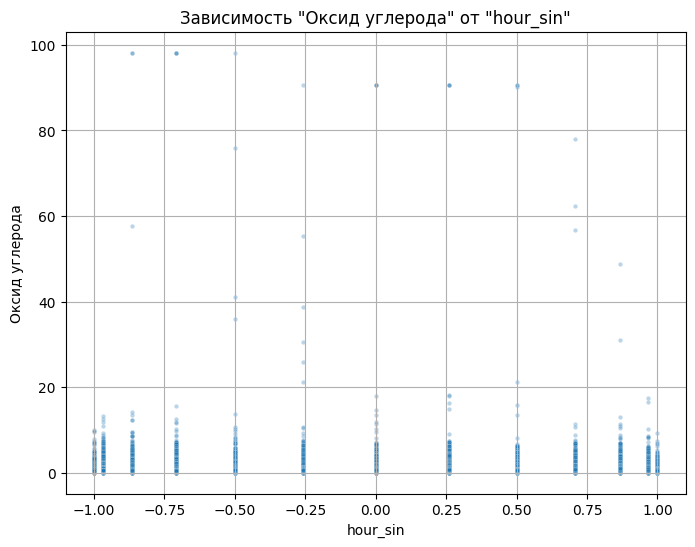

Для признака 'station_id_st_07' используется Boxplot для исходной колонки 'station_id'.
Для признака 'station_id_st_26' используется Boxplot для исходной колонки 'station_id'.
Для признака 'station_id_tr_05' используется Boxplot для исходной колонки 'station_id'.

График зависимости 'Оксид углерода' от 'Сероводород':


/tmp/ipython-input-4256295902.py:41: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  elif feature in df_model.columns and df_model[feature].dtype in [np.number] and feature != 'station_id':


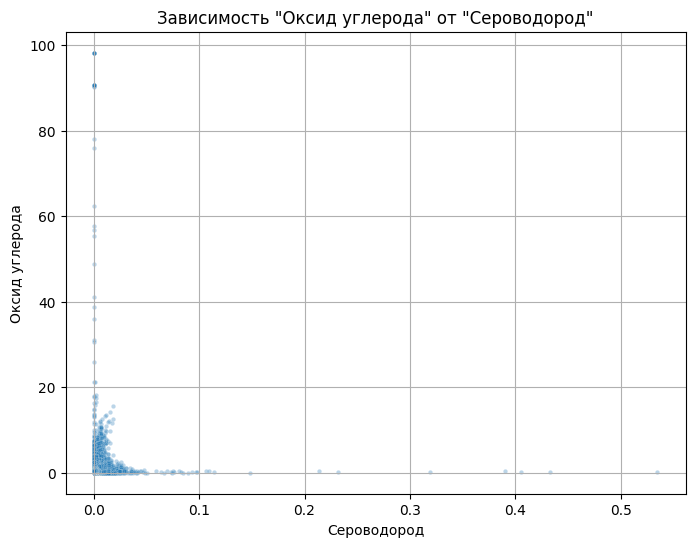


График зависимости 'Оксид углерода' от 'Скорость ветра':


/tmp/ipython-input-4256295902.py:41: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  elif feature in df_model.columns and df_model[feature].dtype in [np.number] and feature != 'station_id':


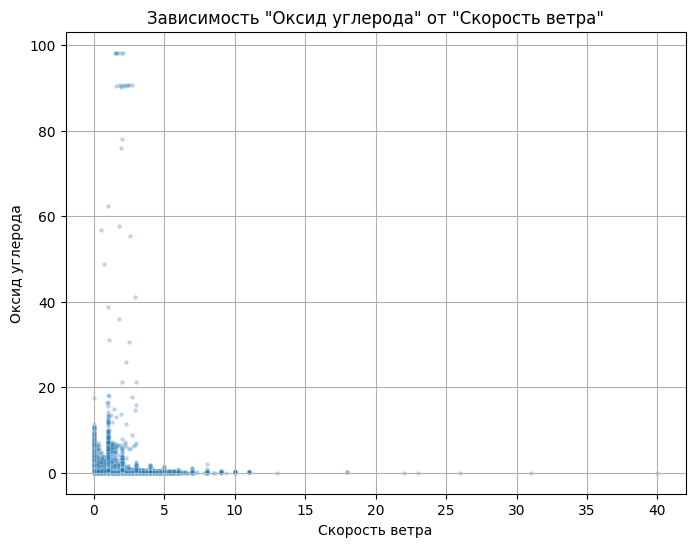


График зависимости 'Оксид углерода' от 'час':


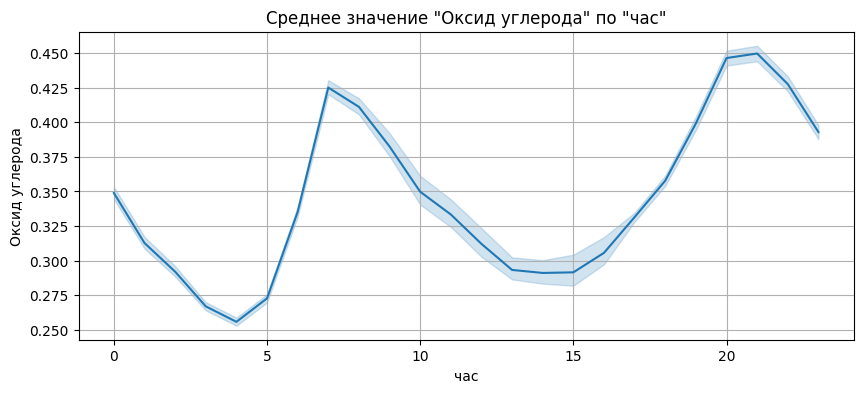

In [ ]:
# Предполагается, что perm_series (Permutation Importance) была рассчитана ранее и доступна.

# Выбираем топ-10 наиболее важных признаков (исключая лаги целевой переменной, т.к. их влияние очевидно)
top_features_processed = perm_series[~perm_series.index.str.contains(TARGET + '_lag')].head(10).index.tolist()

# Удаляем префиксы 'remainder__' и 'cat__' для доступа к колонкам в исходном df_model
top_features = [feature.replace('remainder__', '').replace('cat__', '') for feature in top_features_processed]

print(f"\n--- Визуализация зависимости от топ-{len(top_features)} ключевых признаков ---")

for feature in top_features:
    # Пропускаем one-hot закодированные признаки станций для scatter plot
    if feature.startswith('station_id_'):
         print(f"Для признака '{feature}' используется Boxplot для исходной колонки 'station_id'.")
         continue

    print(f"\nГрафик зависимости '{TARGET}' от '{feature}':")

    if feature in ['час', 'день_недели', 'месяц']: # Временные признаки
        plt.figure(figsize=(10, 4))
        # Используем df_model, так как он содержит все признаки и целевую переменную
        sns.lineplot(x=feature, y=TARGET, data=df_model)
        plt.title(f'Среднее значение "{TARGET}" по "{feature}"')
        plt.xlabel(feature)
        plt.ylabel(TARGET)
        plt.grid(True)
        plt.show()

    elif feature == 'station_id': # Категориальный признак
        plt.figure(figsize=(12, 6))
        sns.boxplot(x=feature, y=TARGET, data=df_model)
        plt.title(f'Распределение "{TARGET}" по "{feature}" (станциям)')
        plt.xlabel(feature)
        plt.ylabel(TARGET)
        plt.xticks(rotation=45, ha='right')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    # Числовые признаки, исключая 'station_id'
    elif feature in df_model.columns and df_model[feature].dtype in [np.number] and feature != 'station_id':
        plt.figure(figsize=(8, 6))
        sns.scatterplot(x=feature, y=TARGET, data=df_model, alpha=0.3, s=10)
        plt.title(f'Зависимость "{TARGET}" от "{feature}"')
        plt.xlabel(feature)
        plt.ylabel(TARGET)
        plt.grid(True)
        plt.show()
    else:
        print(f"Для признака '{feature}' не определен тип графика или признак отсутствует в df_model.")